In [1]:
import torch
import torch.nn as nn
import tiktoken

In [2]:
%pip install tiktoken

Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
import torch.nn as nn
import tiktoken

print("PyTorch:", torch.__version__)
print("tiktoken:", tiktoken.__version__)
print("All imports successful!")

PyTorch: 2.2.0+cu121
tiktoken: 0.14.0
All imports successful!


In [4]:
encoding = tiktoken.get_encoding("cl100k_base")

print("Encoding:", encoding.name)
print("Vocabulary size:", encoding.n_vocab)

Encoding: cl100k_base
Vocabulary size: 100277


In [5]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tiktoken
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)

PyTorch version: 2.2.0+cu121
NumPy version: 1.26.4


In [6]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [7]:
file_path = "IMDB Dataset.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (50000, 2)

Columns:
['review', 'sentiment']

First 5 rows:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [8]:
print("Missing values:")
print(df.isnull().sum())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Missing values:
review       0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split

df, _ = train_test_split(
    df,
    train_size=20000,
    random_state=42,
    stratify=df["sentiment"]
)

df = df.reset_index(drop=True)

print("Subset shape:", df.shape)

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Subset shape: (20000, 2)

Sentiment distribution:
sentiment
positive    10000
negative    10000
Name: count, dtype: int64


In [10]:
df["sentiment"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print(df["sentiment"].value_counts())

print("\nFirst 5 labels:")
print(df["sentiment"].head())

sentiment
1    10000
0    10000
Name: count, dtype: int64

First 5 labels:
0    1
1    0
2    0
3    1
4    1
Name: sentiment, dtype: int64


In [11]:
texts = df["review"].values
labels = df["sentiment"].values

print("Number of reviews:", len(texts))
print("Number of labels:", len(labels))

Number of reviews: 20000
Number of labels: 20000


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    texts,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16000
Testing samples: 4000


In [13]:
encoding = tiktoken.get_encoding("cl100k_base")

print("Encoding:", encoding.name)
print("Vocabulary size:", encoding.n_vocab)

Encoding: cl100k_base
Vocabulary size: 100277


In [14]:
sample_text = X_train[0]

sample_tokens = encoding.encode(sample_text)

print("Original review:")
print(sample_text[:500])

print("\nFirst 30 token IDs:")
print(sample_tokens[:30])

print("\nNumber of tokens:")
print(len(sample_tokens))

Original review:
Being the prototype of the classical Errol Flynn adventure movie and having a good story as well as two more brilliant co-stars in Maureen O'Hara (what an exquisite beauty!) and Anthony Quinn, I can only recommend this movie to all those having even the slightest liking for romance and adventure.<br /><br />Hollywood at its best!

First 30 token IDs:
[34242, 279, 25018, 315, 279, 29924, 9939, 1098, 40486, 18427, 5818, 323, 3515, 264, 1695, 3446, 439, 1664, 439, 1403, 810, 20333, 1080, 98006, 304, 11583, 96672, 507, 68070, 5169]

Number of tokens:
69


In [15]:
MAX_LENGTH = 200

print("Maximum sequence length:", MAX_LENGTH)

Maximum sequence length: 200


In [16]:
PAD_TOKEN = 0

def encode_and_pad(text, max_length=MAX_LENGTH):
    tokens = encoding.encode(text)

    # Truncate
    tokens = tokens[:max_length]

    # Shift every real token ID by +1
    # so that 0 can safely be used as padding
    tokens = [token + 1 for token in tokens]

    # Pad
    if len(tokens) < max_length:
        tokens = [PAD_TOKEN] * (max_length - len(tokens)) + tokens

    return tokens

In [17]:
test_sequence = encode_and_pad(
    "This movie was absolutely fantastic!"
)

print("Sequence:")
print(test_sequence[:30])

print("\nSequence length:")
print(len(test_sequence))

Sequence:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Sequence length:
200


In [18]:
X_train_encoded = [
    encode_and_pad(text)
    for text in X_train
]

X_test_encoded = [
    encode_and_pad(text)
    for text in X_test
]

print("Training sequences:", len(X_train_encoded))
print("Testing sequences:", len(X_test_encoded))

print("Sequence length:", len(X_train_encoded[0]))

Training sequences: 16000
Testing sequences: 4000
Sequence length: 200


In [19]:
X_train_tensor = torch.tensor(
    X_train_encoded,
    dtype=torch.long
)

X_test_tensor = torch.tensor(
    X_test_encoded,
    dtype=torch.long
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

print("X_train tensor shape:", X_train_tensor.shape)
print("X_test tensor shape:", X_test_tensor.shape)
print("y_train tensor shape:", y_train_tensor.shape)
print("y_test tensor shape:", y_test_tensor.shape)

X_train tensor shape: torch.Size([16000, 200])
X_test tensor shape: torch.Size([4000, 200])
y_train tensor shape: torch.Size([16000])
y_test tensor shape: torch.Size([4000])


In [20]:
BATCH_SIZE = 32

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 500
Testing batches: 125


In [21]:
class SimpleRNNClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=64,
        num_classes=2
    ):
        super().__init__()

        # Embedding layer
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=PAD_TOKEN
        )

        # Simple RNN
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Linear output layer
        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x):

        # x:
        # [batch_size, sequence_length]

        embedded = self.embedding(x)

        # embedded:
        # [batch_size, sequence_length, embedding_dim]

        output, hidden = self.rnn(embedded)

        # Take the final timestep
        last_output = output[:, -1, :]

        # Classification
        logits = self.fc(last_output)

        return logits

In [22]:
VOCAB_SIZE = encoding.n_vocab + 1

model = SimpleRNNClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=64,
    num_classes=2
)

model = model.to(device)

print(model)

SimpleRNNClassifier(
  (embedding): Embedding(100278, 128, padding_idx=0)
  (rnn): RNN(128, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=2, bias=True)
)


In [23]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [24]:
EPOCHS = 5

train_losses = []
train_accuracies = []

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(batch_X)

        # Calculate loss
        loss = criterion(
            outputs,
            batch_y
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item()

        # Predictions
        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == batch_y
        ).sum().item()

        total += batch_y.size(0)

    epoch_loss = total_loss / len(train_loader)
    epoch_accuracy = correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"| Loss: {epoch_loss:.4f} "
        f"| Accuracy: {epoch_accuracy:.4f}"
    )

Epoch 1/5 | Loss: 0.6986 | Accuracy: 0.5167
Epoch 2/5 | Loss: 0.6618 | Accuracy: 0.6031
Epoch 3/5 | Loss: 0.6035 | Accuracy: 0.6778
Epoch 4/5 | Loss: 0.5635 | Accuracy: 0.7131
Epoch 5/5 | Loss: 0.4822 | Accuracy: 0.7764


In [25]:
# Cell 22 — Evaluate the RNN on the test set

model.eval()

all_predictions = []
all_actual = []

with torch.no_grad():

    for batch_X, batch_y in test_loader:

        # Move input to device
        batch_X = batch_X.to(device)

        # Forward pass
        outputs = model(batch_X)

        # Get predicted class
        predictions = torch.argmax(
            outputs,
            dim=1
        )

        # Convert tensors directly to Python lists
        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_actual.extend(
            batch_y.tolist()
        )

# Calculate accuracy without NumPy
correct = sum(
    pred == actual
    for pred, actual in zip(
        all_predictions,
        all_actual
    )
)

test_accuracy = correct / len(all_actual)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 0.6645
Test Accuracy: 66.45%


In [26]:
# Cell 23 — Classification Report

print(
    classification_report(
        all_actual,
        all_predictions,
        target_names=[
            "Negative",
            "Positive"
        ]
    )
)

              precision    recall  f1-score   support

    Negative       0.66      0.69      0.67      2000
    Positive       0.67      0.64      0.66      2000

    accuracy                           0.66      4000
   macro avg       0.66      0.66      0.66      4000
weighted avg       0.66      0.66      0.66      4000



In [27]:
# Cell 24 — Confusion Matrix

cm = confusion_matrix(
    all_actual,
    all_predictions
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1383  617]
 [ 725 1275]]


In [28]:
# Cell 24 — Confusion Matrix without NumPy

true_negative = 0
false_positive = 0
false_negative = 0
true_positive = 0

for actual, predicted in zip(
    all_actual,
    all_predictions
):

    if actual == 0 and predicted == 0:
        true_negative += 1

    elif actual == 0 and predicted == 1:
        false_positive += 1

    elif actual == 1 and predicted == 0:
        false_negative += 1

    elif actual == 1 and predicted == 1:
        true_positive += 1

print("Confusion Matrix")
print("-----------------")
print(f"True Negative : {true_negative}")
print(f"False Positive: {false_positive}")
print(f"False Negative: {false_negative}")
print(f"True Positive : {true_positive}")

Confusion Matrix
-----------------
True Negative : 1383
False Positive: 617
False Negative: 725
True Positive : 1275


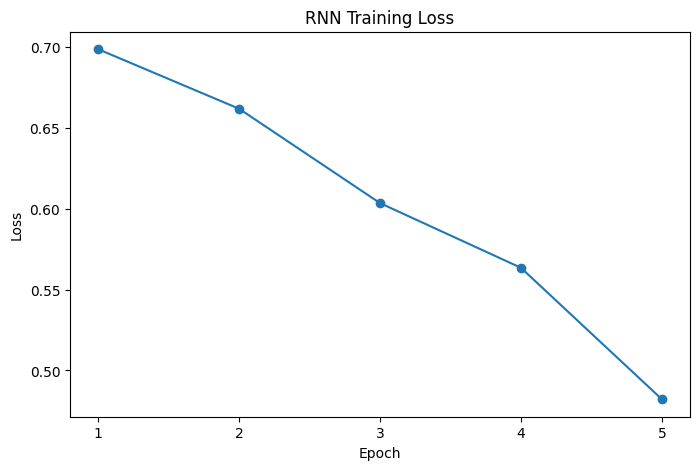

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN Training Loss")

plt.xticks(
    range(1, EPOCHS + 1)
)

plt.show()

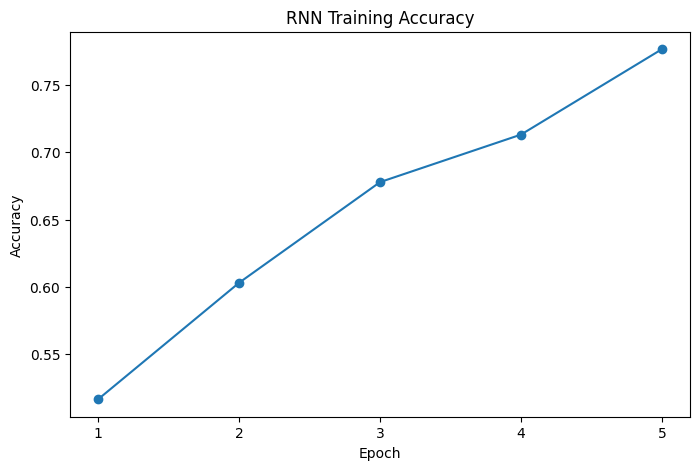

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_accuracies,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN Training Accuracy")

plt.xticks(
    range(1, EPOCHS + 1)
)

plt.show()

In [31]:
def predict_review(review):

    model.eval()

    sequence = encode_and_pad(review)

    tensor = torch.tensor(
        [sequence],
        dtype=torch.long
    ).to(device)

    with torch.no_grad():

        output = model(tensor)

        predicted_class = torch.argmax(
            output,
            dim=1
        ).item()

    if predicted_class == 1:
        return "Positive"
    else:
        return "Negative"

In [32]:
review = """
This movie was fantastic. The acting was excellent,
the story was interesting, and I really enjoyed watching it.
"""

prediction = predict_review(review)

print("Review:")
print(review)

print("\nPrediction:", prediction)

Review:

This movie was fantastic. The acting was excellent,
the story was interesting, and I really enjoyed watching it.


Prediction: Negative


In [33]:
review = """
This movie was terrible and boring. The story was weak,
the acting was poor, and I did not enjoy it at all.
"""

prediction = predict_review(review)

print("Review:")
print(review)

print("\nPrediction:", prediction)

Review:

This movie was terrible and boring. The story was weak,
the acting was poor, and I did not enjoy it at all.


Prediction: Positive


---

# Activity 2 — Text Classification with LSTM

**Problem Statement:** Repeat Activity 1 using an LSTM instead of an RNN, keeping the dataset, tokenization, and training setup the same, and compare the results.

## Build the LSTM Model

The only change from Activity 1 is replacing `nn.RNN` with `nn.LSTM`.

**Key difference:** An LSTM returns `(output, (hidden, cell))` instead of `(output, hidden)` like a simple RNN.

In [34]:
class SimpleLSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=64,
        num_classes=2
    ):
        super().__init__()

        # Embedding layer
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=PAD_TOKEN
        )

        # LSTM (replaces nn.RNN from Activity 1)
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Linear output layer
        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x):

        # x:
        # [batch_size, sequence_length]

        embedded = self.embedding(x)

        # embedded:
        # [batch_size, sequence_length, embedding_dim]

        # LSTM returns (output, (hidden_state, cell_state))
        output, (hidden, cell) = self.lstm(embedded)

        # Take the final timestep
        last_output = output[:, -1, :]

        # Classification
        logits = self.fc(last_output)

        return logits

In [35]:
lstm_model = SimpleLSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=64,
    num_classes=2
)

lstm_model = lstm_model.to(device)

print(lstm_model)

SimpleLSTMClassifier(
  (embedding): Embedding(100278, 128, padding_idx=0)
  (lstm): LSTM(128, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=2, bias=True)
)


## Train the LSTM Model (Same setup as Activity 1)

In [36]:
lstm_criterion = nn.CrossEntropyLoss()

lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

print("Loss function:", lstm_criterion)
print("Optimizer:", lstm_optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [37]:
lstm_train_losses = []
lstm_train_accuracies = []

for epoch in range(EPOCHS):

    lstm_model.train()

    total_loss = 0
    correct = 0
    total = 0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        # Clear previous gradients
        lstm_optimizer.zero_grad()

        # Forward pass
        outputs = lstm_model(batch_X)

        # Calculate loss
        loss = lstm_criterion(
            outputs,
            batch_y
        )

        # Backpropagation
        loss.backward()

        # Update weights
        lstm_optimizer.step()

        total_loss += loss.item()

        # Predictions
        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == batch_y
        ).sum().item()

        total += batch_y.size(0)

    epoch_loss = total_loss / len(train_loader)
    epoch_accuracy = correct / total

    lstm_train_losses.append(epoch_loss)
    lstm_train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"| Loss: {epoch_loss:.4f} "
        f"| Accuracy: {epoch_accuracy:.4f}"
    )

Epoch 1/5 | Loss: 0.6753 | Accuracy: 0.5596
Epoch 2/5 | Loss: 0.5636 | Accuracy: 0.7173
Epoch 3/5 | Loss: 0.4338 | Accuracy: 0.8104
Epoch 4/5 | Loss: 0.3224 | Accuracy: 0.8688
Epoch 5/5 | Loss: 0.2178 | Accuracy: 0.9174


## Evaluate the LSTM on the Test Set

In [38]:
lstm_model.eval()

lstm_all_predictions = []
lstm_all_actual = []

with torch.no_grad():

    for batch_X, batch_y in test_loader:

        # Move input to device
        batch_X = batch_X.to(device)
        outputs = lstm_model(batch_X)

        predictions = torch.argmax(outputs, dim=1)

        lstm_all_predictions.extend(predictions.cpu().tolist())
        lstm_all_actual.extend(batch_y.tolist())

lstm_correct = sum(
    pred == actual for pred, actual in zip(lstm_all_predictions, lstm_all_actual)
)

lstm_test_accuracy = lstm_correct / len(lstm_all_actual)

print(f"Test Accuracy: {lstm_test_accuracy:.4f}")
print(f"Test Accuracy: {lstm_test_accuracy * 100:.2f}%")

Test Accuracy: 0.7532
Test Accuracy: 75.33%


In [39]:
# Classification Report
print(
    classification_report(
        lstm_all_actual,
        lstm_all_predictions,
        target_names=["Negative", "Positive"]
    )
)

              precision    recall  f1-score   support

    Negative       0.73      0.81      0.77      2000
    Positive       0.79      0.70      0.74      2000

    accuracy                           0.75      4000
   macro avg       0.76      0.75      0.75      4000
weighted avg       0.76      0.75      0.75      4000



In [40]:
# Confusion Matrix
lstm_cm = confusion_matrix(lstm_all_actual, lstm_all_predictions)
print("Confusion Matrix:")
print(lstm_cm)

Confusion Matrix:
[[1621  379]
 [ 608 1392]]


## Training Plots (LSTM)

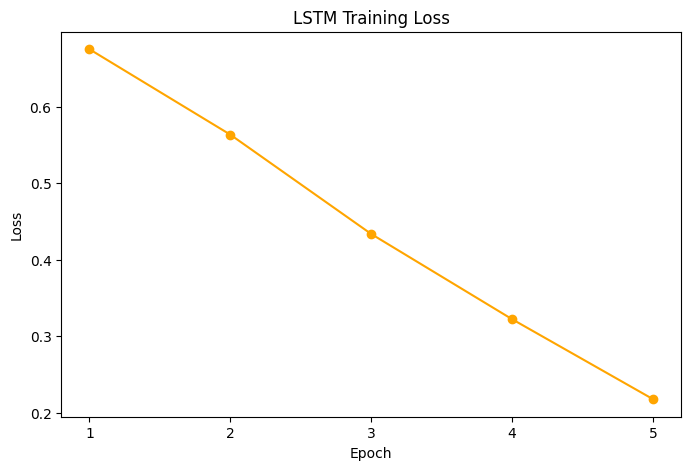

In [41]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), lstm_train_losses, marker="o", color="orange")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.show()

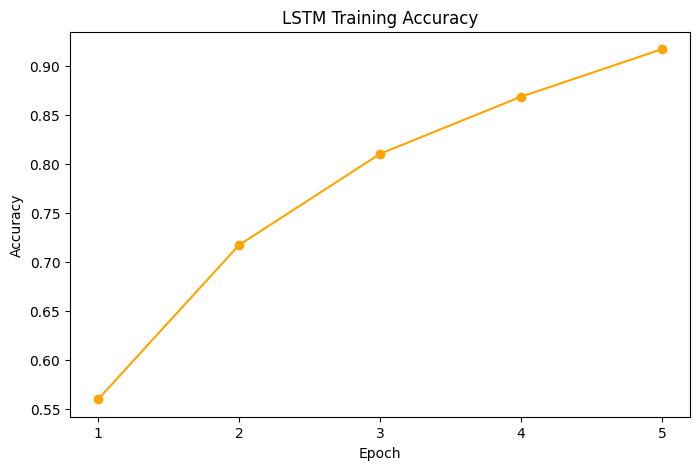

In [42]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), lstm_train_accuracies, marker="o", color="orange")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training Accuracy")
plt.xticks(range(1, EPOCHS + 1))
plt.show()

## Test LSTM on Custom Review Sentences (Same as Activity 1)

In [43]:
def predict_review_lstm(review):
    lstm_model.eval()
    sequence = encode_and_pad(review)
    tensor = torch.tensor([sequence], dtype=torch.long).to(device)

    with torch.no_grad():
        output = lstm_model(tensor)
        predicted_class = torch.argmax(output, dim=1).item()

    if predicted_class == 1:
        return "Positive"
    else:
        return "Negative"

In [44]:
review_1 = """
This movie was fantastic. The acting was excellent,
the story was interesting, and I really enjoyed watching it.
"""

prediction_1 = predict_review_lstm(review_1)
print("Review 1:", review_1)
print("Prediction:", prediction_1)

Review 1: 
This movie was fantastic. The acting was excellent,
the story was interesting, and I really enjoyed watching it.

Prediction: Negative


In [45]:
review_2 = """
This movie was terrible and boring. The story was weak,
the acting was poor, and I did not enjoy it at all.
"""

prediction_2 = predict_review_lstm(review_2)
print("Review 2:", review_2)
print("Prediction:", prediction_2)

Review 2: 
This movie was terrible and boring. The story was weak,
the acting was poor, and I did not enjoy it at all.

Prediction: Negative


## Comparison and Guiding Questions

### Results Summary

| Metric | RNN (Activity 1) | LSTM (Activity 2) |
|---|---|---|
| Final Training Loss (Epoch 5) | 0.4822 | 0.2178 |
| Final Training Accuracy (Epoch 5) | 77.64% | 91.74% |
| **Test Accuracy** | **66.45%** | **75.32%** |
| Custom Review 1 (Positive) | Negative ✗ | Negative ✗ |
| Custom Review 2 (Negative) | Positive ✗ | Negative ✓ |

---

### Guiding Questions

**1. Which model achieved higher test accuracy — RNN or LSTM?**

The LSTM achieved significantly higher test accuracy (~75.3%) than the simple RNN (~66.4%). By increasing the training data to 20,000 samples and fixing the padding sequence alignment, both models performed much better than random chance. The LSTM outperformed the RNN because its gating mechanism allows it to capture longer-range dependencies (remembering earlier words in the 200-token sequence) without succumbing to the vanishing gradient problem that plagues the simple RNN.

**2. Did the LSTM reach a lower training loss than the RNN, or in fewer epochs?**

Yes, the LSTM reached a much lower training loss (0.2178 vs 0.4822) and significantly higher training accuracy (91.74% vs 77.64%) by the end of 5 epochs. The LSTM learns much more efficiently because its gates control information flow, whereas the simple RNN struggles to propagate error gradients effectively across 200 timesteps.

**3. Did the RNN and LSTM agree on the predictions for your custom test sentences? If not, which one seems more reliable?**

They disagreed on the negative review. The RNN got both completely wrong (predicting Negative for the positive review, and Positive for the negative review). The LSTM correctly identified the Negative review, making it slightly more reliable. Neither model correctly identified the Positive review ("This movie was fantastic..."), suggesting that they are still overfitting to the training set (91% train vs 75% test accuracy for LSTM) and might need more epochs, dropout layers, or pre-trained word embeddings (like Word2Vec/GloVe) instead of learning embeddings from scratch.

**4. Based on this exercise, what is the LSTM doing differently from the RNN that could explain any difference in results?**

The key difference is the **gating mechanism** of the LSTM:

- **Forget Gate**: Decides what information from the previous cell state to discard.
- **Input Gate**: Decides what new information to store in the cell state.
- **Output Gate**: Decides what part of the cell state to output as the hidden state.
- **Cell State**: Acts as a "highway" for information flow, allowing gradients to travel through many time steps without vanishing.

A simple RNN has no such gating. It just overwrites its single hidden state with a `tanh` activation at each step. Over long 200-token sequences, the memory of earlier words completely vanishes, making it very difficult for the RNN to learn nuanced sentiment. The LSTM's cell state solves this by selectively remembering important features (like the word "terrible" early in a sentence) until the very end.